# 🧹 Limpieza de Datos con Pandas
### Análisis y depuración del dataset *Dirty Financial Transactions*

## Introducción

En este taller se realizará un proceso de **diagnóstico, limpieza y transformación de datos utilizando Python y la librería Pandas**.

Se trabajará con el dataset **Dirty Financial Transactions**, el cual contiene información sobre transacciones financieras y presenta diferentes problemas de calidad, como valores faltantes, registros duplicados, inconsistencias en datos categóricos, formatos incorrectos, fechas inválidas y valores fuera de rango.

El objetivo es identificar estos problemas y aplicar diferentes técnicas de limpieza para obtener un conjunto de datos más consistente, organizado y preparado para su posterior análisis.

## 1. Concepto y propósito de la limpieza de datos

La **limpieza de datos** es el proceso de identificar, corregir o eliminar información incorrecta, incompleta, duplicada o inconsistente dentro de un conjunto de datos.

Su propósito principal es **mejorar la calidad y confiabilidad de la información**, ya que trabajar con datos incorrectos puede generar resultados poco precisos y afectar las conclusiones obtenidas durante un análisis.

En este caso, se realizará la limpieza del dataset *Dirty Financial Transactions* con el objetivo de corregir diferentes problemas presentes en los registros antes de utilizarlos para un análisis posterior.

---

## 2. Problemas comunes de calidad de datos

Dentro de una base de datos pueden presentarse diferentes problemas que afectan la calidad de la información. Algunos de los más comunes son:

- **Valores faltantes:** información que no fue registrada o aparece como vacía.
- **Registros duplicados:** filas que se encuentran repetidas dentro del dataset.
- **Inconsistencias de texto:** diferentes formas de representar una misma categoría.
- **Errores tipográficos:** palabras incompletas o escritas de manera incorrecta.
- **Espacios innecesarios:** espacios adicionales antes o después de los valores.
- **Formatos incorrectos:** números almacenados como texto o acompañados de símbolos.
- **Fechas inválidas:** fechas imposibles o almacenadas en formatos incorrectos.
- **Valores fuera de rango:** cantidades negativas, valores excesivamente altos o datos que no son coherentes con la variable analizada.

En el dataset *Dirty Financial Transactions* se pueden encontrar varios de estos problemas, por lo que será necesario identificarlos y corregirlos utilizando diferentes herramientas de **Pandas**.

## 1. Preparación del entorno

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from io import StringIO
import json

# Carpetas de trabajo
Path("data/raw").mkdir(parents=True, exist_ok=True)       # Datos en bruto
Path("data/processed").mkdir(parents=True, exist_ok=True) # Datos procesados y limpios
Path("reports").mkdir(parents=True, exist_ok=True)        # Gráficas y reportes obtenidos

pd.set_option("display.max_columns", 50)

print("Entorno preparado.")

Entorno preparado.


# 2. Carga del dataset

In [ ]:

from google.colab import files
from pathlib import Path

# Carpeta donde se guardarán los datos originales
raw_path = Path("data/raw")
raw_path.mkdir(parents=True, exist_ok=True)

print("Selecciona el archivo CSV:")
uploaded = files.upload()

# Guardar el archivo dentro de data/raw
for filename, content in uploaded.items():
    file_path = raw_path / filename

    with open(file_path, "wb") as f:
        f.write(content)

    print(f"Archivo guardado correctamente en: {file_path}")

dataset_path = Path("data/raw/dirty_financial_transactions.csv")

df = pd.read_csv(dataset_path)

print("Dataset cargado correctamente.")



Selecciona el archivo CSV:


Saving dirty_financial_transactions.csv to dirty_financial_transactions.csv
Archivo guardado correctamente en: data/raw/dirty_financial_transactions.csv
Dataset cargado correctamente.


# 3. Diagnostico inicial del dataset


## 3.1 Visualización de los primeros registros

In [ ]:
print("PRIMEROS 5 REGISTROS DEL DATASET")
display(df.head())

PRIMEROS 5 REGISTROS DEL DATASET


,Transaction_ID,Transaction_Date,Customer_ID,Product_Name,Quantity,Price,Payment_Method,Transaction_Status
0,T0001,2024-08-02,C2205,Headphones,-5.0,$420.21,pay pal,NaN
1,T0002,2020-02-10,C3156,Coffee,469.0,-445.34202525395585,creditcard,Pending
2,T0003,2025-02-30,C2919,Tablet,-4.0,810.9930123946459,credit card,completed
3,T0004,2020-08-17,C3009,Tab,-7.0,868.6083413217348,PayPal,Pending
4,T0005,2025-02-30,C3488,Coffee Machine,-10.0,-763.1224490039416,PayPal,completed


##3.2 Dimensiones

In [ ]:
filas, columnas = df.shape

print("\nDIMENSIONES DEL DATASET")
print("Cantidad de filas:", filas)
print("Cantidad de columnas:", columnas)



DIMENSIONES DEL DATASET
Cantidad de filas: 100000
Cantidad de columnas: 8


## 3.3 Información general

In [ ]:
print("\nINFORMACIÓN GENERAL DEL DATASET")
df.info()


INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Transaction_ID      94982 non-null   object 
 1   Transaction_Date    95120 non-null   object 
 2   Customer_ID         95122 non-null   object 
 3   Product_Name        100000 non-null  object 
 4   Quantity            94981 non-null   float64
 5   Price               66503 non-null   object 
 6   Payment_Method      100000 non-null  object 
 7   Transaction_Status  83321 non-null   object 
dtypes: float64(1), object(7)
memory usage: 6.1+ MB


## 3.4 Valores faltantes

In [ ]:
valores_faltantes = df.isnull().sum()
porcentaje_faltantes = (valores_faltantes / len(df)) * 100

resumen_faltantes = pd.DataFrame({
    "Valores faltantes": valores_faltantes,
    "Porcentaje (%)": porcentaje_faltantes.round(2)
})

print("\nVALORES FALTANTES POR COLUMNA")
display(resumen_faltantes)



VALORES FALTANTES POR COLUMNA


,Valores faltantes,Porcentaje (%)
Transaction_ID,5018,5.02
Transaction_Date,4880,4.88
Customer_ID,4878,4.88
Product_Name,0,0.00
Quantity,5019,5.02
Price,33497,33.50
Payment_Method,0,0.00
Transaction_Status,16679,16.68


## 3.5 Registros duplicados

In [ ]:
duplicados = df.duplicated().sum()

print("\nREGISTROS DUPLICADOS")
print("Cantidad de registros duplicados:", duplicados)


# Mostrar algunos duplicados
print("\nEJEMPLOS DE REGISTROS DUPLICADOS")
display(df[df.duplicated(keep=False)].head(6))


# Mostrar registros duplicados agrupados para ver las copias juntas
print("\nEJEMPLOS DE REGISTROS DUPLICADOS AJUNTADOS")
duplicados_df = df[df.duplicated(keep=False)].copy()

# Ordenar por todas las columnas para colocar las filas idénticas una al lado de la otra
duplicados_ordenados = duplicados_df.sort_values(
    by=list(df.columns),
    na_position="first"
)

display(duplicados_ordenados.head(6))


REGISTROS DUPLICADOS
Cantidad de registros duplicados: 994

EJEMPLOS DE REGISTROS DUPLICADOS


,Transaction_ID,Transaction_Date,Customer_ID,Product_Name,Quantity,Price,Payment_Method,Transaction_Status
26,T73466,2025-02-30,C2702,Coffee Machine,-5.0,555.6133483579025,creditcard,complete
141,T77766,2023-13-01,C4226,Tablet,-7.0,$862.48,Credit Card,complete
161,T17515,2024-11-25,C3287,Smartphone,-9.0,850.4985899006939,Credit Card,Pending
323,T22566,NaN,C530,Smartphone,365.0,$103.82,PayPal,complete
359,T66876,2023-13-01,C4712,Headphones,-5.0,776.5305169596752,PayPal,NaN
395,NaN,2025-02-30,C4267,Tablet,-9.0,-897.0577631812591,Credit Card,Pending



EJEMPLOS DE REGISTROS DUPLICADOS AJUNTADOS


,Transaction_ID,Transaction_Date,Customer_ID,Product_Name,Quantity,Price,Payment_Method,Transaction_Status
34827,NaN,2020-03-04,C3547,Coffee Machine,6.0,NaN,Credit Card,Pending
87097,NaN,2020-03-04,C3547,Coffee Machine,6.0,NaN,Credit Card,Pending
25733,NaN,2020-05-03,C3042,Tablet,-8.0,NaN,PayPal,completed
37871,NaN,2020-05-03,C3042,Tablet,-8.0,NaN,PayPal,completed
15269,NaN,2020-10-10,C1634,Laptop,6.0,683.1762759085898,credit card,Completed
33194,NaN,2020-10-10,C1634,Laptop,6.0,683.1762759085898,credit card,Completed


### Bitácora de decisiones

A partir de aquí documentamos cada decisión de limpieza que se toma (columna afectada, problema detectado, acción tomada y justificación). Esta bitácora se sigue usando en todo el notebook, incluida la parte final de comparación.

In [ ]:
decisiones = []

def registrar_decision(columna, problema, accion, justificacion):
    decisiones.append({
        'Columna': columna,
        'Problema detectado': problema,
        'Acción tomada': accion,
        'Justificación': justificacion
    })

print("Bitácora inicializada.")

Bitácora inicializada.


# 4. Normalizacion de nombres de columnas
La normalización de los nombres de las columnas consiste en aplicar un formato uniforme para facilitar su lectura y manipulación dentro del código.

En este caso, aunque los nombres originales del dataset ya son relativamente claros, utilizan mayúsculas y guiones bajos de forma combinada, por ejemplo:

- `Transaction_ID`
- `Transaction_Date`
- `Customer_ID`
- `Product_Name`

Para mantener una estructura consistente, se transformarán todos los nombres a minúsculas, se eliminarán espacios innecesarios y se utilizará el formato `snake_case`.

Esto facilita el acceso a las columnas y reduce posibles errores al escribir sus nombres durante el análisis.

In [ ]:
# Mostrar nombres originales
print("NOMBRES ORIGINALES DE LAS COLUMNAS:")
print(df.columns.tolist())


# Normalizar nombres de columnas
df.columns = (
    df.columns
      .str.strip()                          # Eliminar espacios al inicio y al final
      .str.lower()                          # Convertir todo a minúsculas
      .str.replace(" ", "_", regex=False)   # Reemplazar espacios por "_"
      .str.replace("-", "_", regex=False)   # Reemplazar guiones por "_"
)


# Mostrar nombres normalizados
print("\nNOMBRES NORMALIZADOS DE LAS COLUMNAS:")
print(df.columns.tolist())
df.head()

NOMBRES ORIGINALES DE LAS COLUMNAS:
['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'Product_Name', 'Quantity', 'Price', 'Payment_Method', 'Transaction_Status']

NOMBRES NORMALIZADOS DE LAS COLUMNAS:
['transaction_id', 'transaction_date', 'customer_id', 'product_name', 'quantity', 'price', 'payment_method', 'transaction_status']


,transaction_id,transaction_date,customer_id,product_name,quantity,price,payment_method,transaction_status
0,T0001,2024-08-02,C2205,Headphones,-5.0,$420.21,pay pal,NaN
1,T0002,2020-02-10,C3156,Coffee,469.0,-445.34202525395585,creditcard,Pending
2,T0003,2025-02-30,C2919,Tablet,-4.0,810.9930123946459,credit card,completed
3,T0004,2020-08-17,C3009,Tab,-7.0,868.6083413217348,PayPal,Pending
4,T0005,2025-02-30,C3488,Coffee Machine,-10.0,-763.1224490039416,PayPal,completed


In [ ]:
registrar_decision(
    columna='nombres de columnas',
    problema='Encabezados con mayusculas y guiones bajos inconsistentes (ej. Transaction_ID, Customer_ID)',
    accion='Se convirtieron a snake_case: minusculas, sin espacios, con guion bajo',
    justificacion='Facilita el acceso a las columnas en el codigo y reduce errores de escritura'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 1


# 5. Limpieza de texto y categorías

Las variables de texto pueden contener problemas como espacios innecesarios, diferencias entre mayúsculas y minúsculas, errores tipográficos o distintas formas de representar una misma categoría.

En el dataset *Dirty Financial Transactions* se encontraron inconsistencias principalmente en las columnas:

- `payment_method`
- `transaction_status`
- `product_name`

Por ejemplo, un mismo método de pago aparece representado como `Credit Card`, `credit card` y `creditcard`. De igual forma, el estado de una transacción puede aparecer como `Completed`, `completed` o `complete`.

También se encontraron nombres de productos incompletos, como `Lapto`, `Lapt`, `Smartph`, `Headphon` o `Coffee Mach`.

El objetivo de esta etapa es eliminar espacios innecesarios y unificar estas diferentes representaciones para obtener categorías consistentes.



## 5.1 LIMPIEZA DE TEXTO Y CATEGORÍAS

In [ ]:
print("MÉTODOS DE PAGO ANTES DE LA LIMPIEZA")
print(df["payment_method"].value_counts(dropna=False))

print("\nESTADOS DE TRANSACCIÓN ANTES DE LA LIMPIEZA")
print(df["transaction_status"].value_counts(dropna=False))

print("\nPRODUCTOS ANTES DE LA LIMPIEZA")
print(df["product_name"].value_counts(dropna=False))

MÉTODOS DE PAGO ANTES DE LA LIMPIEZA
payment_method
Credit Card    14433
creditcard     14384
pay pal        14357
PayPal         14262
Cash           14212
credit card    14198
PayPal         14154
Name: count, dtype: int64

ESTADOS DE TRANSACCIÓN ANTES DE LA LIMPIEZA
transaction_status
Failed       16795
complete     16717
completed    16687
NaN          16679
Pending      16595
Completed    16527
Name: count, dtype: int64

PRODUCTOS ANTES DE LA LIMPIEZA
product_name
Tablet            18444
Laptop            18264
Smartphone        18257
Headphones        18107
Coffee Machine    18085
Lapt                370
Table               352
La                  347
Tabl                346
Lapto               344
Ta                  344
T                   335
Lap                 334
Tab                 330
L                   321
Smartph             234
S                   223
H                   217
He                  212
Smart               206
Head                204
Smartp              20

##5.2 Eliminar espacios innecesarios

Ahora limpiamos espacios al inicio y final de las columnas de texto:


*   "PayPal " → "PayPal"
*   "Coffee " → "Coffee"




In [ ]:
# Identificar las columnas de texto
columnas_texto = df.select_dtypes(include="object").columns

# Eliminar espacios innecesarios al inicio y al final
for columna in columnas_texto:
    df[columna] = df[columna].str.strip()

print("Espacios innecesarios eliminados.")

Espacios innecesarios eliminados.


In [ ]:
registrar_decision(
    columna='columnas de texto (todas)',
    problema='Espacios en blanco al inicio/final en varios valores (ej. "PayPal ", "Coffee ")',
    accion='Se aplico str.strip() a todas las columnas de tipo texto',
    justificacion='Evita que "PayPal" y "PayPal " se traten como dos categorias distintas'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 2


##5.3 Normalizar métodos de pago, estados de las transacciones

Aquí unificamos las distintas formas de representar el mismo método:

*   Credit Card
*   credit card
*   creditcard

quedan como:

*   Credit Card


In [ ]:
# Normalizar métodos de pago

df["payment_method"] = df["payment_method"].str.lower()

df["payment_method"] = df["payment_method"].replace({
    "creditcard": "Credit Card",
    "credit card": "Credit Card",
    "paypal": "PayPal",
    "pay pal": "PayPal",
    "cash": "Cash"
})

print("MÉTODOS DE PAGO DESPUÉS DE LA LIMPIEZA")
print(df["payment_method"].value_counts(dropna=False))
print(" ")
print(" ")

# Normalizar estados de las transacciones

df["transaction_status"] = df["transaction_status"].str.strip().str.lower()

df["transaction_status"] = df["transaction_status"].replace({
    "complete": "Completed",
    "completed": "Completed",
    "pending": "Pending",
    "failed": "Failed"
})

print("ESTADOS DESPUÉS DE LA LIMPIEZA")
print(df["transaction_status"].value_counts(dropna=False))




MÉTODOS DE PAGO DESPUÉS DE LA LIMPIEZA
payment_method
Credit Card    43015
PayPal         42773
Cash           14212
Name: count, dtype: int64
 
 
ESTADOS DESPUÉS DE LA LIMPIEZA
transaction_status
Completed    49931
Failed       16795
NaN          16679
Pending      16595
Name: count, dtype: int64


In [ ]:
registrar_decision(
    columna='payment_method',
    problema='Multiples variantes del mismo metodo de pago (Credit Card / credit card / creditcard, PayPal / pay pal)',
    accion='Se paso todo a minusculas y se unifico con un diccionario de reemplazo',
    justificacion='Evita fragmentar el analisis en categorias que en realidad representan el mismo metodo'
)
registrar_decision(
    columna='transaction_status',
    problema='Variantes del mismo estado (complete / completed / Completed)',
    accion='Se aplico strip + minusculas y se unifico con un diccionario de reemplazo',
    justificacion='Necesario para poder agrupar correctamente las transacciones por estado'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 4


##5.4 Corregir nombres de productos

* Tablet
* Table
* Tabl
* Tab
* Ta
* T

In [ ]:
# Función para normalizar los nombres de los productos

def limpiar_producto(producto):

    if pd.isna(producto):
        return producto

    producto = producto.strip().lower()

    if producto.startswith("l"):
        return "Laptop"

    elif producto.startswith("t"):
        return "Tablet"

    elif producto.startswith("s"):
        return "Smartphone"

    elif producto.startswith("h"):
        return "Headphones"

    elif producto.startswith("c"):
        return "Coffee Machine"

    else:
        return producto


# Aplicar la función
df["product_name"] = df["product_name"].apply(limpiar_producto)

print("PRODUCTOS DESPUÉS DE LA LIMPIEZA")
print(df["product_name"].value_counts(dropna=False))

PRODUCTOS DESPUÉS DE LA LIMPIEZA
product_name
Tablet            20151
Smartphone        20067
Laptop            19980
Headphones        19934
Coffee Machine    19868
Name: count, dtype: int64


In [ ]:
registrar_decision(
    columna='product_name',
    problema='Nombres de producto truncados en distintos niveles (ej. "Lapto", "Smartph", "Coffee Mach")',
    accion='Se creo una funcion que identifica el producto por su primera letra y lo reemplaza por el nombre completo',
    justificacion='Permite recuperar la categoria real del producto sin descartar esos registros'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 5


##5.5 Verificación final

In [ ]:
print("CATEGORÍAS FINALES\n")

print("Métodos de pago:")
print(df["payment_method"].unique())

print("\nEstados de transacción:")
print(df["transaction_status"].unique())

print("\nProductos:")
print(df["product_name"].unique())

CATEGORÍAS FINALES

Métodos de pago:
['PayPal' 'Credit Card' 'Cash']

Estados de transacción:
[nan 'Pending' 'Completed' 'Failed']

Productos:
['Headphones' 'Coffee Machine' 'Tablet' 'Smartphone' 'Laptop']


# 6. Identificación y reemplazo de códigos de valores faltantes

En algunos conjuntos de datos, los valores faltantes no aparecen directamente como `NaN`, sino que pueden estar representados mediante códigos o textos especiales como:

- `?`
- `N/A`
- `NA`
- `Unknown`
- `NULL`
- `None`
- `-999`
- Cadenas vacías o espacios en blanco

Estos valores pueden pasar desapercibidos durante un análisis de datos, ya que Pandas puede interpretarlos como texto o incluso como valores numéricos válidos.

Por esta razón, antes de continuar con la limpieza se realizará una búsqueda de posibles códigos utilizados para representar información faltante.

En el dataset *Dirty Financial Transactions*, los valores ausentes se encuentran principalmente como celdas vacías, las cuales Pandas ya interpreta como `NaN`. Sin embargo, se comprobará si existen otras representaciones ocultas.

##6.1 Buscar posibles códigos de valores faltantes

In [ ]:
# ============================================================
# 6. IDENTIFICACIÓN DE CÓDIGOS DE VALORES FALTANTES
# ============================================================

# Posibles códigos utilizados para representar valores faltantes
codigos_faltantes_texto = [
    "?",
    "N/A",
    "NA",
    "n/a",
    "na",
    "Unknown",
    "UNKNOWN",
    "unknown",
    "NULL",
    "null",
    "None",
    "none",
    "",
    " "
]

print("BÚSQUEDA DE POSIBLES CÓDIGOS DE VALORES FALTANTES\n")

# Revisar únicamente columnas de texto
columnas_texto = df.select_dtypes(include="object").columns

encontrados = {}

for columna in columnas_texto:
    conteo = df[columna].isin(codigos_faltantes_texto).sum()

    if conteo > 0:
        encontrados[columna] = conteo
        print(f"{columna}: {conteo} posibles códigos faltantes")

if not encontrados:
    print("No se encontraron códigos especiales de valores faltantes en las columnas de texto.")

BÚSQUEDA DE POSIBLES CÓDIGOS DE VALORES FALTANTES

No se encontraron códigos especiales de valores faltantes en las columnas de texto.


##6.2 Comprobar códigos numéricos especiales
Como también se suelen utilizar números como -999 o 9999 para representar información faltante, podemos buscarlos por separado.

In [ ]:
# Posibles códigos numéricos o valores extremos

codigos_especiales = [-999, 999, 9999, -9999]

print("BÚSQUEDA DE POSIBLES CÓDIGOS O VALORES EXTREMOS\n")

columnas_numericas = df.select_dtypes(include=["number"]).columns

for columna in columnas_numericas:
    for codigo in codigos_especiales:

        cantidad = (df[columna] == codigo).sum()

        if cantidad > 0:
            print(
                f"Columna '{columna}': "
                f"{cantidad} registros con el valor {codigo}"
            )

print("\nNota: estos valores no se reemplazan automáticamente por NaN.")
print("Primero debe determinarse si representan datos faltantes o valores fuera de rango.")



BÚSQUEDA DE POSIBLES CÓDIGOS O VALORES EXTREMOS

Columna 'quantity': 33 registros con el valor 999

Nota: estos valores no se reemplazan automáticamente por NaN.
Primero debe determinarse si representan datos faltantes o valores fuera de rango.


##6.3 Reemplazar los códigos encontrados por NaN
Aunque en nuestro dataset no esperamos encontrar esos códigos, este sería el procedimiento correcto para convertirlos en valores faltantes reconocidos por Pandas:

In [ ]:
# Reemplazar códigos de texto por NaN

df[columnas_texto] = df[columnas_texto].replace(
    codigos_faltantes_texto,
    np.nan
)

print("Códigos de texto reemplazados por NaN.")

# Verificar valores faltantes después de la revisión

valores_faltantes = df.isnull().sum()
porcentaje_faltantes = (valores_faltantes / len(df)) * 100

resumen_faltantes = pd.DataFrame({
    "Valores faltantes": valores_faltantes,
    "Porcentaje (%)": porcentaje_faltantes.round(2)
})

display(resumen_faltantes)

Códigos de texto reemplazados por NaN.


,Valores faltantes,Porcentaje (%)
transaction_id,5018,5.02
transaction_date,4880,4.88
customer_id,4878,4.88
product_name,0,0.00
quantity,5019,5.02
price,33497,33.50
payment_method,0,0.00
transaction_status,16679,16.68


In [ ]:
registrar_decision(
    columna='valores faltantes codificados',
    problema='Se buscaron codigos ocultos de datos faltantes (?, N/A, NULL, -999, 9999, etc.)',
    accion='No se encontraron codigos especiales; los valores faltantes ya estaban representados como NaN',
    justificacion='Confirma que no hace falta ninguna conversion adicional antes de seguir con el resto de la limpieza'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 6


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.width', 120)

# Partimos del DataFrame ya cargado y normalizado en la seccion anterior
# (nombres de columnas en snake_case, texto y categorias limpias).
# Guardamos una copia de este punto para comparar antes/despues al cierre de esta seccion.
df_crudo = df.copy()

## 1. Corrección de formatos numéricos y conversión de tipos

Cuando pandas lee un CSV, si una columna numérica trae caracteres como `$`, comas de miles, espacios o texto mezclado, la interpreta como texto (`object`) en vez de número. Mientras eso pase, **no podemos sumar, promediar ni comparar** esos valores.

Revisemos los tipos actuales de `price` y `quantity`:

In [ ]:
display(df[['price', 'quantity']].dtypes.to_frame('Tipo actual'))
display(df[['transaction_id', 'price', 'quantity']].sample(6, random_state=1))

,Tipo actual
price,object
quantity,float64


,transaction_id,price,quantity
43660,T43661,-659.904543926184,2.0
87278,T87279,NaN,924.0
14317,T14318,-856.3336952865458,2.0
81932,T81933,$-65.29,386.0
95321,T95322,486.5093325477953,4.0
5405,T5406,NaN,-5.0


`price` es de tipo `object` porque algunos valores vienen con símbolo de moneda (`$420.21`) y otros como número "limpio" en texto (`-445.34...`). La estrategia:

1. Convertir a texto por seguridad (`astype(str)`).
2. Quitar `$` y comas de miles con una expresión regular.
3. Convertir a numérico con `pd.to_numeric(..., errors='coerce')`, que transforma cualquier valor no convertible en `NaN` en lugar de detener el proceso.

De paso, aplicamos `pd.to_numeric` también a `quantity` como buena práctica defensiva, aunque ya haya sido inferida como numérica.

In [ ]:
# 1) Quitamos simbolos de moneda y comas de miles, luego convertimos a numerico
df['price'] = df['price'].astype(str).str.replace(r'[\$,]', '', regex=True)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Buena practica: asegurar tipo numerico tambien en quantity
df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')

print("Tipos despues de la conversion:")
display(df[['price', 'quantity']].dtypes.to_frame('Tipo nuevo'))
display(df[['transaction_id', 'price', 'quantity']].sample(6, random_state=1))

Tipos despues de la conversion:


,Tipo nuevo
price,float64
quantity,float64


,transaction_id,price,quantity
43660,T43661,-659.904544,2.0
87278,T87279,NaN,924.0
14317,T14318,-856.333695,2.0
81932,T81933,-65.290000,386.0
95321,T95322,486.509333,4.0
5405,T5406,NaN,-5.0


In [ ]:
registrar_decision(
    columna='price',
    problema="Almacenada como texto (object); mezcla de formato '$420.21' y '-445.34...' sin simbolo",
    accion="Se eliminaron simbolos '$' y comas, y se convirtio con pd.to_numeric(errors='coerce')",
    justificacion="Es indispensable que price sea numerico (float) para poder operarlo (ej. calcular el total de la transaccion)"
)
registrar_decision(
    columna='quantity',
    problema='Ya era numerica, pero sin una conversion explicita no hay garantia de que se mantenga asi',
    accion="Se forzo con pd.to_numeric(errors='coerce') como practica defensiva",
    justificacion='Evita fallas silenciosas si en el futuro llegan valores no numericos en esta columna'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 8


## 2. Identificación de valores imposibles o fuera de rango

Ahora que `price` y `quantity` son numéricas, podemos aplicar **reglas de negocio** para detectar valores que, aunque técnicamente son números válidos, no tienen sentido en el mundo real:

- Un **precio negativo** no existe.
- Una **cantidad negativa** de unidades vendidas tampoco (una devolución se registraría en otra columna, no como una venta negativa).

Revisemos qué tan grave es el problema antes de decidir qué hacer:

In [ ]:
neg_price = (df['price'] < 0).sum()
neg_qty = (df['quantity'] < 0).sum()

print(f"Precios negativos  : {neg_price:,}  de {df['price'].notnull().sum():,} valores no nulos")
print(f"Cantidades negativas: {neg_qty:,}  de {df['quantity'].notnull().sum():,} valores no nulos")
print()
print("Estadisticas de price (incluye negativos):")
display(df['price'].describe().to_frame())
print("Estadisticas de quantity (incluye negativos):")
display(df['quantity'].describe().to_frame())

Precios negativos  : 33,195  de 66,503 valores no nulos
Cantidades negativas: 31,619  de 94,981 valores no nulos

Estadisticas de price (incluye negativos):


,price
count,66503.000000
mean,0.667244
std,592.518730
min,-999.968903
25%,-526.101656
50%,51.608527
75%,524.778940
max,999.987698


Estadisticas de quantity (incluye negativos):


,quantity
count,94981.000000
mean,183.883914
std,299.292365
min,-10.000000
25%,-3.000000
50%,6.000000
75%,327.000000
max,1000.000000


Los dos casos **no son iguales** y por eso los tratamos distinto:

- **`price`**: el rango de los valores negativos es prácticamente un espejo del rango positivo (de -1000 a 1000 aprox., simétrico alrededor de cero). Esto es consistente con un **error de signo** en la captura de datos (por ejemplo, un descuento o una resta que quedó mal aplicada), no con un precio genuinamente distinto. Por eso corregimos tomando el **valor absoluto**: conservamos la magnitud, que sí parece confiable, y corregimos solo el signo.
- **`quantity`**: los valores negativos están concentrados en un rango angosto (-10 a -1), muy distinto al rango positivo (hasta 1000). Si fuera un simple error de signo esperaríamos que el rango negativo reflejara todo el rango positivo, y no es el caso. No podemos asumir con confianza cuál era el valor real, así que lo marcamos como **dato no confiable (`NaN`)** para tratarlo explícitamente en la sección de datos faltantes.

> Esta es una decisión de negocio, no una regla universal de pandas — en un caso real se validaría con el área correspondiente antes de aplicarla.

In [ ]:
# Precio: se asume error de signo -> se corrige con valor absoluto
df.loc[df['price'] < 0, 'price'] = df.loc[df['price'] < 0, 'price'].abs()

# Cantidad: no se puede confiar en la magnitud -> se marca como faltante
df.loc[df['quantity'] < 0, 'quantity'] = np.nan

print("Verificacion despues de la correccion:")
print(f"Precios negativos restantes   : {(df['price'] < 0).sum()}")
print(f"Cantidades negativas restantes: {(df['quantity'] < 0).sum()}")
print(f"Nuevos NaN en quantity (antes eran negativos): {df['quantity'].isnull().sum():,}")

Verificacion despues de la correccion:
Precios negativos restantes   : 0
Cantidades negativas restantes: 0
Nuevos NaN en quantity (antes eran negativos): 36,638


In [ ]:
registrar_decision(
    columna='price',
    problema=f'{neg_price:,} precios negativos; el rango negativo es simetrico al positivo',
    accion='Se corrigieron con valor absoluto (abs)',
    justificacion='Patron consistente con error de signo en la captura; la magnitud del numero se conserva como dato util'
)
registrar_decision(
    columna='quantity',
    problema=f'{neg_qty:,} cantidades negativas, concentradas en un rango angosto (-10 a -1) que no refleja el rango positivo',
    accion='Se marcaron como NaN (dato no confiable) en lugar de corregirlas con abs()',
    justificacion='No hay evidencia de que sea un simple error de signo; es mas seguro tratarlas como faltantes que inventar un valor'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 11


## 3. Manejo y conversión de fechas

`transaction_date` también llega como texto. Para trabajar con fechas de verdad (filtrar por rango, extraer año/mes, ordenar cronológicamente) necesitamos convertirla con `pd.to_datetime()`.

Usamos `errors='coerce'`: cualquier valor que **no sea una fecha válida** (por ejemplo un mes 13, o el 30 de febrero, que no existe) se convierte en `NaT` (*Not a Time*, el equivalente a `NaN` para fechas) en lugar de romper la ejecución.

In [ ]:
fechas_originales = df['transaction_date'].copy()

df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')

# Detectamos las fechas que SI tenian texto pero no se pudieron convertir (invalidas, no vacias)
mask_invalidas = fechas_originales.notnull() & df['transaction_date'].isnull()

print(f"Valores de fecha vacios desde el origen : {fechas_originales.isnull().sum():,}")
print(f"Valores de fecha con formato invalido    : {mask_invalidas.sum():,}")
print(f"Total de fechas no utilizables            : {df['transaction_date'].isnull().sum():,}")

Valores de fecha vacios desde el origen : 4,880
Valores de fecha con formato invalido    : 63,381
Total de fechas no utilizables            : 68,261


Veamos **cuáles** eran esos valores inválidos más frecuentes — esto nos ayuda a entender si es ruido aleatorio o un patrón:

In [ ]:
display(
    fechas_originales[mask_invalidas]
    .value_counts()
    .head(10)
    .to_frame('Frecuencia')
)

,Frecuencia
transaction_date,
2023-13-01,31834
2025-02-30,31547


Se observa que casi todas las fechas inválidas corresponden a **solo dos valores que se repiten miles de veces**: `2023-13-01` (mes 13 no existe) y `2025-02-30` (febrero nunca tiene 30 días). Esto sugiere que no son errores de tecleo aleatorios, sino **valores centinela** que el sistema de origen usó como marcador de "fecha desconocida" — un patrón muy común en datos reales, y justamente el tipo de cosa que `pd.to_datetime(errors='coerce')` está diseñado para atrapar.

In [ ]:
registrar_decision(
    columna='transaction_date',
    problema="Texto en vez de fecha; ademas contiene valores invalidos recurrentes ('2023-13-01', '2025-02-30') que actuan como centinelas de 'fecha desconocida'",
    accion="Conversion con pd.to_datetime(errors='coerce'); los valores invalidos quedan como NaT",
    justificacion='Sin una fecha real no es posible ordenar, filtrar por periodo ni construir columnas de anio/mes de forma confiable'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 9


## 4. Detección y eliminación de duplicados

Revisamos duplicados de dos formas:

1. **Fila completa duplicada** (`df.duplicated()`): probablemente el mismo registro se cargó dos veces.
2. **`transaction_id` duplicado** (excluyendo los ID vacíos, que no deben compararse entre sí): un mismo identificador no debería representar dos transacciones distintas.

In [ ]:
dup_completos = df.duplicated().sum()
print(f"Filas 100% duplicadas: {dup_completos:,}")
display(df[df.duplicated(keep=False)].sort_values('transaction_id').head(6))

Filas 100% duplicadas: 999


,transaction_id,transaction_date,customer_id,product_name,quantity,price,payment_method,transaction_status
96769,T0580,NaT,C747,Smartphone,NaN,583.843158,PayPal,Completed
579,T0580,NaT,C747,Smartphone,NaN,583.843158,PayPal,Completed
31589,T0657,NaT,C3153,Coffee Machine,123.0,NaN,PayPal,NaN
656,T0657,NaT,C3153,Coffee Machine,123.0,NaN,PayPal,NaN
92916,T0998,NaT,C2150,Smartphone,NaN,NaN,PayPal,Completed
997,T0998,NaT,C2150,Smartphone,NaN,NaN,PayPal,Completed


In [ ]:
# Eliminamos las filas totalmente duplicadas (nos quedamos con la primera aparicion)
df = df.drop_duplicates()

# Ahora revisamos IDs duplicados, excluyendo los que son nulos
mask_id_valido = df['transaction_id'].notnull()
dup_id = df.loc[mask_id_valido, 'transaction_id'].duplicated().sum()
print(f"transaction_id duplicados (con ID valido): {dup_id:,}")

if dup_id > 0:
    idx_a_eliminar = df.loc[mask_id_valido].loc[
        df.loc[mask_id_valido, 'transaction_id'].duplicated()
    ].index
    df = df.drop(index=idx_a_eliminar)

print(f"Filas despues de eliminar duplicados: {df.shape[0]:,}")

transaction_id duplicados (con ID valido): 0
Filas despues de eliminar duplicados: 99,001


In [ ]:
registrar_decision(
    columna='(fila completa) y transaction_id',
    problema=f'{dup_completos:,} filas totalmente duplicadas; posibles IDs repetidos adicionales',
    accion='drop_duplicates() sobre la fila completa, luego sobre transaction_id (ignorando IDs nulos), conservando la primera aparicion',
    justificacion='Una transaccion no deberia contarse dos veces; contarla dos veces infla artificialmente los totales financieros'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 12


## 5. Tratamiento de datos faltantes

Veamos el panorama actual de valores faltantes (incluye los `NaN`/`NaT` que generamos nosotros mismos en los pasos 2 y 3, además de los que ya venían vacíos en el archivo original):

In [ ]:
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(1)
resumen_nulos = pd.DataFrame({'Nulos': nulos, '% del total': porcentaje})
display(resumen_nulos[resumen_nulos['Nulos'] > 0].sort_values('Nulos', ascending=False))

,Nulos,% del total
transaction_date,67561,68.2
quantity,36277,36.6
price,33126,33.5
transaction_status,16521,16.7
transaction_id,4961,5.0
customer_id,4825,4.9


No todas las columnas merecen el mismo tratamiento. La estrategia por columna:

| Columna | Estrategia | Motivo |
|---|---|---|
| `transaction_id` | Eliminar la fila | Sin un identificador único, la transacción no se puede rastrear ni conciliar |
| `transaction_date` | Eliminar la fila | No se puede "inventar" una fecha para un movimiento financiero sin distorsionar cualquier análisis temporal |
| `customer_id` | Rellenar con `"Desconocido"` | No es crítico para el análisis financiero agregado; perder la fila completa por esto sería desperdiciar datos válidos de precio/cantidad |
| `quantity` | Imputar con la **mediana** | La mediana es robusta a valores extremos; permite conservar la fila para el cálculo de totales |
| `price` | Imputar con la **mediana** | Misma lógica que `quantity` |
| `transaction_status` | Rellenar con `"Sin registrar"` | Es informativo, no bloquea el análisis financiero central |

Aplicamos esto en orden: primero eliminamos filas (porque no tiene sentido imputar el resto de columnas de una fila que de todos modos vamos a descartar), y luego imputamos lo que queda.

In [ ]:
filas_antes = df.shape[0]

# --- Eliminar filas sin identificador o sin fecha valida ---
df = df[df['transaction_id'].notnull()]
eliminadas_id = filas_antes - df.shape[0]

filas_antes_fecha = df.shape[0]
df = df[df['transaction_date'].notnull()]
eliminadas_fecha = filas_antes_fecha - df.shape[0]

print(f"Filas eliminadas por transaction_id faltante: {eliminadas_id:,}")
print(f"Filas eliminadas por transaction_date invalida/faltante: {eliminadas_fecha:,}")
print(f"Filas restantes: {df.shape[0]:,}")

Filas eliminadas por transaction_id faltante: 4,961
Filas eliminadas por transaction_date invalida/faltante: 64,180
Filas restantes: 29,860


In [ ]:
# --- Imputaciones ---
faltantes_cliente = df['customer_id'].isnull().sum()
df['customer_id'] = df['customer_id'].fillna('Desconocido')

mediana_qty = df['quantity'].median()
faltantes_qty = df['quantity'].isnull().sum()
df['quantity'] = df['quantity'].fillna(mediana_qty)

mediana_price = df['price'].median()
faltantes_price = df['price'].isnull().sum()
df['price'] = df['price'].fillna(mediana_price)

faltantes_status = df['transaction_status'].isnull().sum()
df['transaction_status'] = df['transaction_status'].fillna('Sin registrar')

print(f"customer_id        -> {faltantes_cliente:,} valores rellenados con 'Desconocido'")
print(f"quantity           -> {faltantes_qty:,} valores imputados con la mediana ({mediana_qty:,.1f})")
print(f"price              -> {faltantes_price:,} valores imputados con la mediana ({mediana_price:,.2f})")
print(f"transaction_status -> {faltantes_status:,} valores rellenados con 'Sin registrar'")
print()
print(f"Nulos restantes en todo el DataFrame: {df.isnull().sum().sum()}")

customer_id        -> 1,450 valores rellenados con 'Desconocido'
quantity           -> 10,811 valores imputados con la mediana (107.0)
price              -> 10,052 valores imputados con la mediana (523.34)
transaction_status -> 4,952 valores rellenados con 'Sin registrar'

Nulos restantes en todo el DataFrame: 0


In [ ]:
registrar_decision('transaction_id', f'{eliminadas_id:,} filas sin identificador', 'Eliminacion de la fila',
                    'No se puede rastrear ni conciliar una transaccion sin ID unico')
registrar_decision('transaction_date', f'{eliminadas_fecha:,} filas sin fecha valida', 'Eliminacion de la fila',
                    'No es posible inventar una fecha sin distorsionar el analisis temporal')
registrar_decision('customer_id', f'{faltantes_cliente:,} valores faltantes', "Relleno con 'Desconocido'",
                    'No es critico para el total financiero; se conserva la transaccion')
registrar_decision('quantity', f'{faltantes_qty:,} valores faltantes (incluye los marcados como invalidos en el paso 3)',
                    f'Imputacion con la mediana ({mediana_qty:,.1f})',
                    'La mediana es robusta a valores extremos y permite conservar la fila')
registrar_decision('price', f'{faltantes_price:,} valores faltantes',
                    f'Imputacion con la mediana ({mediana_price:,.2f})',
                    'Misma logica que quantity: preservar filas sin distorsionar con outliers')
registrar_decision('transaction_status', f'{faltantes_status:,} valores faltantes', "Relleno con 'Sin registrar'",
                    'Es informativo; no bloquea calculos financieros')
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 18


## 6. Creación de columnas después de la limpieza

Con los datos ya limpios (tipos correctos, sin imposibles, sin duplicados, sin faltantes) podemos derivar columnas nuevas con seguridad — si hiciéramos esto **antes** de limpiar, heredaríamos todos los errores (por ejemplo, un total calculado con un precio negativo).

Creamos:
- `total_amount`: `quantity * price`, el valor total de la transacción.
- `año`, `mes`, `dia_semana`: extraídos de `transaction_date`, útiles para análisis por periodo.

In [ ]:
df['total_amount'] = (df['quantity'] * df['price']).round(2)
df['año'] = df['transaction_date'].dt.year
df['mes'] = df['transaction_date'].dt.month
df['dia_semana'] = df['transaction_date'].dt.day_name()

display(df[['transaction_id', 'transaction_date', 'año', 'mes', 'dia_semana',
            'quantity', 'price', 'total_amount']].head(8))

,transaction_id,transaction_date,año,mes,dia_semana,quantity,price,total_amount
0,T0001,2024-08-02,2024,8,Friday,107.0,420.210000,44962.47
1,T0002,2020-02-10,2020,2,Monday,469.0,445.342025,208865.41
3,T0004,2020-08-17,2020,8,Monday,107.0,868.608341,92941.09
5,T0006,2021-10-26,2021,10,Tuesday,598.0,523.340518,312957.63
12,T0013,2020-03-18,2020,3,Wednesday,564.0,523.340518,295164.05
13,T0014,2020-06-19,2020,6,Friday,696.0,905.514730,630238.25
16,T0017,2020-07-07,2020,7,Tuesday,236.0,94.557265,22315.51
18,T0019,2024-02-19,2024,2,Monday,107.0,523.340518,55997.44


In [ ]:
registrar_decision(
    columna='total_amount, anio, mes, dia_semana (nuevas)',
    problema='No existian columnas para el valor total de la transaccion ni para analisis por periodo',
    accion='Se derivaron a partir de columnas ya limpias (quantity, price, transaction_date)',
    justificacion='Se crean DESPUES de limpiar para que no hereden errores de los datos originales'
)
print(f"Decisiones registradas hasta ahora: {len(decisiones)}")

Decisiones registradas hasta ahora: 19


## 7. Documentación de decisiones de limpieza

Documentar cada transformación (qué se hizo, por qué, y a cuántos registros afectó) es tan importante como la limpieza misma: permite que **cualquier otra persona pueda auditar o repetir el proceso**, y evita que decisiones de negocio queden "escondidas" dentro del código.

A continuación, la bitácora completa que fuimos construyendo a lo largo del notebook:

In [ ]:
tabla_decisiones = pd.DataFrame(decisiones)
display(tabla_decisiones.style.set_properties(**{'text-align': 'left'}).set_table_styles(
    [{'selector': 'th', 'props': [('text-align', 'left')]}]
))

,Columna,Problema detectado,Acción tomada,Justificación
0,nombres de columnas,"Encabezados con mayusculas y guiones bajos inconsistentes (ej. Transaction_ID, Customer_ID)","Se convirtieron a snake_case: minusculas, sin espacios, con guion bajo",Facilita el acceso a las columnas en el codigo y reduce errores de escritura
1,columnas de texto (todas),"Espacios en blanco al inicio/final en varios valores (ej. ""PayPal "", ""Coffee "")",Se aplico str.strip() a todas las columnas de tipo texto,"Evita que ""PayPal"" y ""PayPal "" se traten como dos categorias distintas"
2,payment_method,"Multiples variantes del mismo metodo de pago (Credit Card / credit card / creditcard, PayPal / pay pal)",Se paso todo a minusculas y se unifico con un diccionario de reemplazo,Evita fragmentar el analisis en categorias que en realidad representan el mismo metodo
3,transaction_status,Variantes del mismo estado (complete / completed / Completed),Se aplico strip + minusculas y se unifico con un diccionario de reemplazo,Necesario para poder agrupar correctamente las transacciones por estado
4,product_name,"Nombres de producto truncados en distintos niveles (ej. ""Lapto"", ""Smartph"", ""Coffee Mach"")",Se creo una funcion que identifica el producto por su primera letra y lo reemplaza por el nombre completo,Permite recuperar la categoria real del producto sin descartar esos registros
5,valores faltantes codificados,"Se buscaron codigos ocultos de datos faltantes (?, N/A, NULL, -999, 9999, etc.)",No se encontraron codigos especiales; los valores faltantes ya estaban representados como NaN,Confirma que no hace falta ninguna conversion adicional antes de seguir con el resto de la limpieza
6,price,Almacenada como texto (object); mezcla de formato '$420.21' y '-445.34...' sin simbolo,"Se eliminaron simbolos '$' y comas, y se convirtio con pd.to_numeric(errors='coerce')",Es indispensable que price sea numerico (float) para poder operarlo (ej. calcular el total de la transaccion)
7,quantity,"Ya era numerica, pero sin una conversion explicita no hay garantia de que se mantenga asi",Se forzo con pd.to_numeric(errors='coerce') como practica defensiva,Evita fallas silenciosas si en el futuro llegan valores no numericos en esta columna
8,transaction_date,"Texto en vez de fecha; ademas contiene valores invalidos recurrentes ('2023-13-01', '2025-02-30') que actuan como centinelas de 'fecha desconocida'",Conversion con pd.to_datetime(errors='coerce'); los valores invalidos quedan como NaT,"Sin una fecha real no es posible ordenar, filtrar por periodo ni construir columnas de anio/mes de forma confiable"
9,price,"33,195 precios negativos; el rango negativo es simetrico al positivo",Se corrigieron con valor absoluto (abs),Patron consistente con error de signo en la captura; la magnitud del numero se conserva como dato util


## 8. Comparación antes y después de limpiar

Cerramos comparando el DataFrame original (`df_crudo`) contra el resultado final (`df`) en varios frentes: tamaño, tipos de datos, valores nulos y estadísticas descriptivas.

In [ ]:
comparacion_forma = pd.DataFrame({
    'Antes': [df_crudo.shape[0], df_crudo.shape[1]],
    'Despues': [df.shape[0], df.shape[1]]
}, index=['Filas', 'Columnas'])

comparacion_forma.loc['Filas', '% conservado'] = round(df.shape[0] / df_crudo.shape[0] * 100, 1)
display(comparacion_forma)

print(f"\nSe eliminaron {df_crudo.shape[0] - df.shape[0]:,} filas en total "
      f"(duplicados + transaction_id/transaction_date no utilizables).")
print("Se ganaron 4 columnas nuevas derivadas del proceso de limpieza.")

,Antes,Despues,% conservado
Filas,100000,29860,29.9
Columnas,8,12,NaN



Se eliminaron 70,140 filas en total (duplicados + transaction_id/transaction_date no utilizables).
Se ganaron 4 columnas nuevas derivadas del proceso de limpieza.


In [ ]:
tipos_antes = df_crudo.dtypes.rename('Tipo antes')
tipos_despues = df.reindex(columns=df_crudo.columns).dtypes.rename('Tipo despues')
display(pd.concat([tipos_antes, tipos_despues], axis=1))

,Tipo antes,Tipo despues
transaction_id,object,object
transaction_date,object,datetime64[ns]
customer_id,object,object
product_name,object,object
quantity,float64,float64
price,object,float64
payment_method,object,object
transaction_status,object,object


In [ ]:
nulos_antes = df_crudo.isnull().sum().rename('Nulos antes')
nulos_despues = df.reindex(columns=df_crudo.columns).isnull().sum().rename('Nulos despues')
display(pd.concat([nulos_antes, nulos_despues], axis=1))

print(f"\nTotal de valores nulos antes  : {df_crudo.isnull().sum().sum():,}")
print(f"Total de valores nulos despues: {df.isnull().sum().sum():,}")

,Nulos antes,Nulos despues
transaction_id,5018,0
transaction_date,4880,0
customer_id,4878,0
product_name,0,0
quantity,5019,0
price,33497,0
payment_method,0,0
transaction_status,16679,0



Total de valores nulos antes  : 69,971
Total de valores nulos despues: 0


Para `price` y `quantity`, comparamos también las estadísticas descriptivas. Para el "antes" convertimos `price` a número únicamente para poder calcular `describe()` (sin aplicar ninguna corrección), de modo que la comparación sea justa:

In [ ]:
price_antes_numerico = pd.to_numeric(
    df_crudo['price'].astype(str).str.replace(r'[\$,]', '', regex=True), errors='coerce'
)
quantity_antes_numerico = pd.to_numeric(df_crudo['quantity'], errors='coerce')

comparacion_price = pd.concat([
    price_antes_numerico.describe().rename('price - antes'),
    df['price'].describe().rename('price - despues')
], axis=1)
display(comparacion_price)

comparacion_qty = pd.concat([
    quantity_antes_numerico.describe().rename('quantity - antes'),
    df['quantity'].describe().rename('quantity - despues')
], axis=1)
display(comparacion_qty)

,price - antes,price - despues
count,66503.000000,29860.000000
mean,0.667244,523.362790
std,592.518730,223.586597
min,-999.968903,50.130776
25%,-526.101656,405.915000
50%,51.608527,523.340518
75%,524.778940,642.341924
max,999.987698,999.968903


,quantity - antes,quantity - despues
count,94981.000000,29860.000000
mean,183.883914,217.250569
std,299.292365,275.418517
min,-10.000000,1.000000
25%,-3.000000,8.000000
50%,6.000000,107.000000
75%,327.000000,301.000000
max,1000.000000,1000.000000


Nótese que en el "antes" el mínimo de `price` y `quantity` es negativo (valores imposibles), mientras que en el "después" el mínimo es `0` o mayor — evidencia directa de que la corrección del paso 3 funcionó.

Por último, dos gráficos simples que resumen visualmente el efecto de la limpieza:

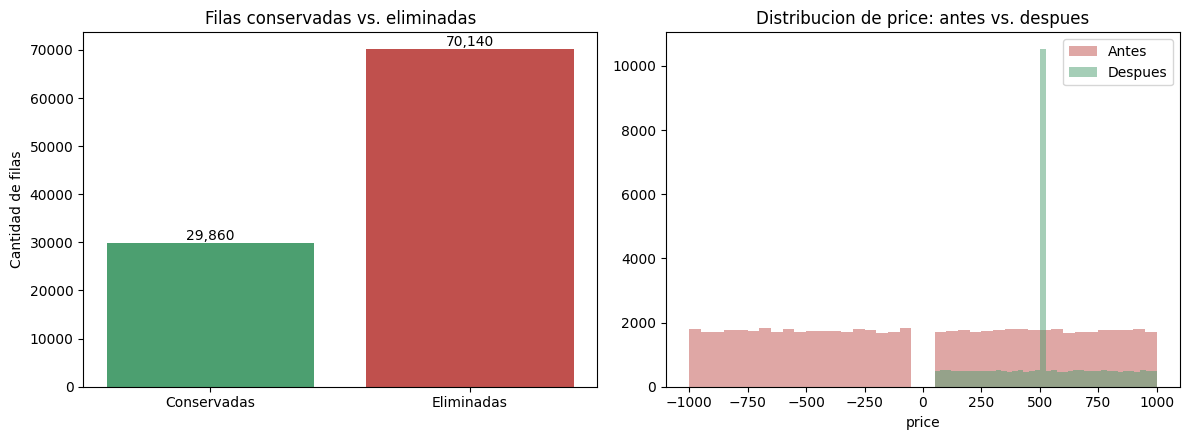

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Grafico 1: filas conservadas vs eliminadas
conservadas = df.shape[0]
eliminadas = df_crudo.shape[0] - df.shape[0]
axes[0].bar(['Conservadas', 'Eliminadas'], [conservadas, eliminadas], color=['#4C9F70', '#C0504D'])
axes[0].set_title('Filas conservadas vs. eliminadas')
axes[0].set_ylabel('Cantidad de filas')
for i, v in enumerate([conservadas, eliminadas]):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

# Grafico 2: distribucion de price antes (con negativos) vs despues
axes[1].hist(price_antes_numerico.dropna(), bins=40, alpha=0.5, label='Antes', color='#C0504D')
axes[1].hist(df['price'], bins=40, alpha=0.5, label='Despues', color='#4C9F70')
axes[1].set_title('Distribucion de price: antes vs. despues')
axes[1].set_xlabel('price')
axes[1].legend()

plt.tight_layout()
plt.show()

## Cierre

Con esto se completa el proceso de limpieza: se corrigieron columnas numericas guardadas como texto, fechas con valores centinela invalidos, valores imposibles (con dos criterios distintos segun lo que mostraba cada distribucion), duplicados, datos faltantes (documentando la decision para cada columna) y se derivaron columnas nuevas sobre datos ya confiables. Se cierra comparando el resultado final contra el dataset original.

El DataFrame `df` queda listo para pasar a un analisis o visualizacion posterior.

In [ ]:
# Opcional: guardar el dataset limpio
df.to_csv('dirty_financial_transactions_clean.csv', index=False)
print("Archivo 'dirty_financial_transactions_clean.csv' guardado.")

Archivo 'dirty_financial_transactions_clean.csv' guardado.
